<a href="https://colab.research.google.com/github/Shivangi-Shah-beep/crossview-masked-image-reconstruction/blob/main/Pretraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os, io, json, zipfile, subprocess, shutil
import numpy as np
from PIL import Image
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
URL = "https://rgbd.cs.princeton.edu/data/SUNRGBD.zip"
IMG = 128
RESAMPLE = Image.BILINEAR        # use the same resize filter as your 7-Scenes cache
DRIVE_DIR = "/content/drive/MyDrive/datasets/sunrgbd"
CACHE = f"{DRIVE_DIR}/sunrgbd_rgb_{IMG}.npz"
LOCAL_ZIP = "/content/SUNRGBD.zip"
KEEP_ZIP_ON_DRIVE = False        # True keeps a 6.4 GB copy on Drive, so you could rebuild at another size later
VAL_FRACTION = 0.05              # small held-out set to watch reconstruction loss
SEED = 0

os.makedirs(DRIVE_DIR, exist_ok=True)


def download():
    drive_zip = f"{DRIVE_DIR}/SUNRGBD.zip"
    if os.path.exists(drive_zip):
        print("zip found on Drive, copying it locally")
        shutil.copy(drive_zip, LOCAL_ZIP)
        return
    print("downloading SUNRGBD.zip (about 6.4 GB)")
    # -c resumes a partial download if the cell is re-run
    subprocess.run(["wget", "-c", "--progress=dot:giga", "-O", LOCAL_ZIP, URL], check=True)
    if KEEP_ZIP_ON_DRIVE:
        shutil.copy(LOCAL_ZIP, drive_zip)


def build_cache():
    images, names, sensors = [], [], []
    seen_scenes, skipped = set(), 0

    with zipfile.ZipFile(LOCAL_ZIP) as zf:
        # RGB frames live in .../<scene>/image/<name>.jpg ; depth and annotations are skipped
        members = sorted(m for m in zf.namelist()
                         if "/image/" in m and m.lower().endswith((".jpg", ".png")))
        print(f"{len(members)} RGB files found")

        for i, m in enumerate(members):
            scene = m.split("/image/")[0]
            if scene in seen_scenes:          # one image per scene
                continue
            try:
                with zf.open(m) as f:
                    img = Image.open(io.BytesIO(f.read())).convert("RGB")
            except Exception:
                skipped += 1
                continue
            images.append(np.asarray(img.resize((IMG, IMG), RESAMPLE), dtype=np.uint8))
            names.append(m)
            sensors.append(m.split("/")[1])   # kv1, kv2, realsense, xtion
            seen_scenes.add(scene)
            if (i + 1) % 1000 == 0:
                print(f"  {i + 1}/{len(members)}")

    images = np.stack(images)                 # (N, 128, 128, 3) uint8
    print(f"kept {len(images)} images, skipped {skipped} unreadable files")

    # Fixed train / val split
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(images))
    n_val = int(len(images) * VAL_FRACTION)
    val_idx, train_idx = np.sort(perm[:n_val]), np.sort(perm[n_val:])

    # Write locally first, then copy: faster and safer than writing a large file to Drive directly
    tmp = f"/content/sunrgbd_rgb_{IMG}.npz"
    np.savez(tmp, images=images, names=np.array(names), sensors=np.array(sensors),
             train_idx=train_idx, val_idx=val_idx)
    shutil.copy(tmp, CACHE)
    os.remove(tmp)

    with open(f"{DRIVE_DIR}/sunrgbd_rgb_{IMG}_info.json", "w") as f:
        json.dump({"source": URL, "img": IMG, "n_images": int(len(images)),
                   "n_train": int(len(train_idx)), "n_val": int(len(val_idx)),
                   "per_sensor": {s: int(sensors.count(s)) for s in set(sensors)}}, f, indent=2)
    print("saved", CACHE)


if os.path.exists(CACHE):
    print("cache already on Drive, nothing to download")
else:
    download()
    build_cache()
    os.remove(LOCAL_ZIP)

cache already on Drive, nothing to download


In [5]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

CACHE = "/content/drive/MyDrive/datasets/sunrgbd/sunrgbd_rgb_128.npz"
IMG = 128

# Use exactly the same MEAN / STD as your pair notebook
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

FLIP_PROB = 0.5
JITTER_PROB = 0.8
COLOR_JITTER = transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05)
CROP = transforms.RandomResizedCrop(IMG, scale=(0.6, 1.0), ratio=(3 / 4, 4 / 3), antialias=True)

data = np.load(CACHE)
all_images = torch.from_numpy(data["images"]).permute(0, 3, 1, 2).contiguous()   # (N, 3, 128, 128) uint8
train_idx, val_idx = data["train_idx"], data["val_idx"]
print("train", len(train_idx), "| val", len(val_idx))


class SingleImageDataset(Dataset):
    def __init__(self, images, idx, train):
        self.images = images
        self.idx = torch.as_tensor(idx)
        self.train = train

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, k):
        img = self.images[self.idx[k]].float() / 255.0            # (3, H, W), 0 to 1
        if self.train:
            if torch.rand(1).item() < FLIP_PROB:
                img = torch.flip(img, dims=[-1])
            img = CROP(img)
            if torch.rand(1).item() < JITTER_PROB:
                img = COLOR_JITTER(img)
        return (img - MEAN) / STD


train_ds = SingleImageDataset(all_images, train_idx, train=True)
val_ds = SingleImageDataset(all_images, val_idx, train=False)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2)

train 9819 | val 516


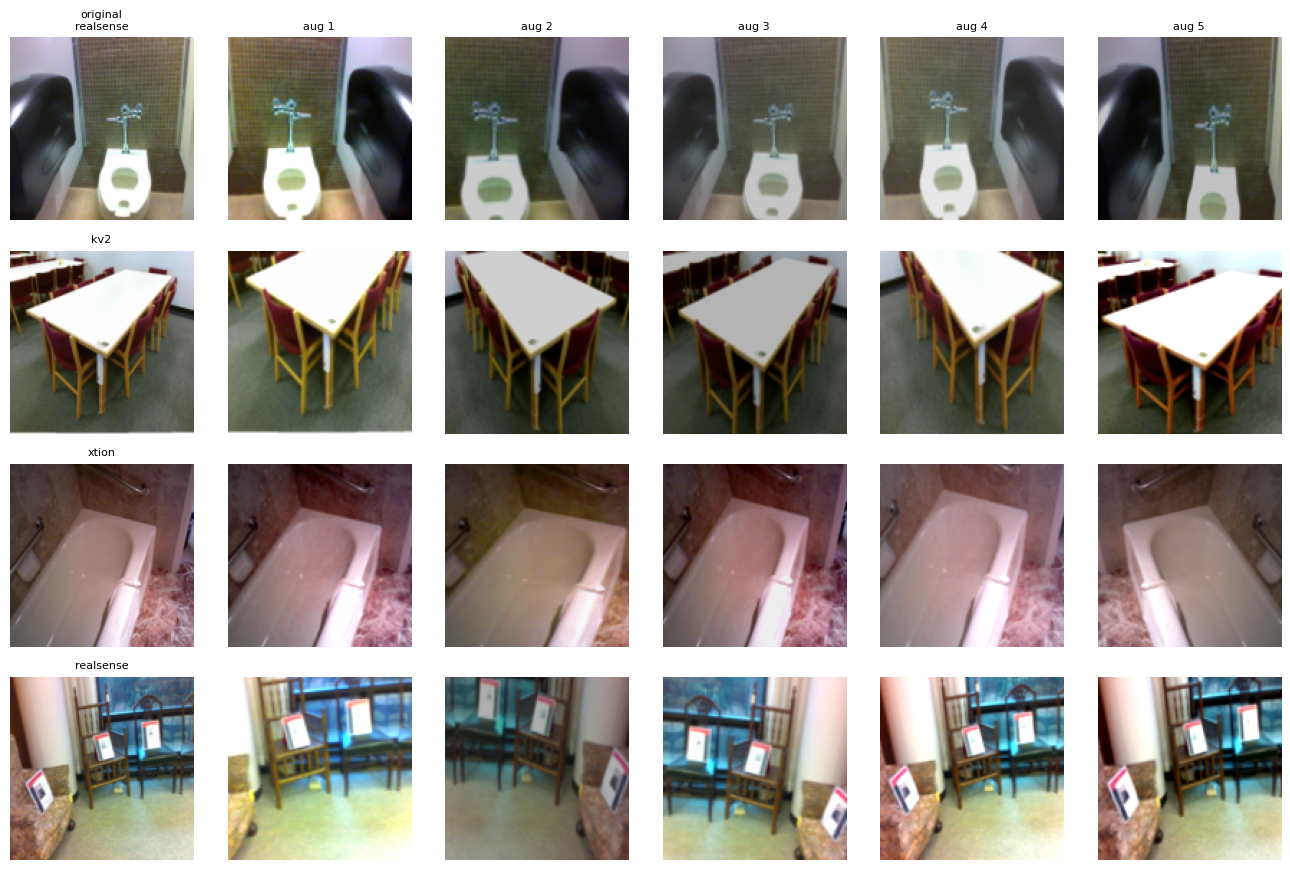

In [6]:
import matplotlib.pyplot as plt

def to_img(x):
    """Undo normalization: (3, H, W) normalized tensor -> (H, W, 3) array in 0 to 1."""
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

def show_samples(n_images=4, n_augs=5, seed=0):
    g = torch.Generator().manual_seed(seed)
    picks = torch.randint(0, len(train_idx), (n_images,), generator=g).tolist()

    # column 0: the clean image (val-style, no augmentation); columns 1+: random augmentations of it
    clean = SingleImageDataset(all_images, train_idx, train=False)

    fig, ax = plt.subplots(n_images, n_augs + 1, figsize=(2.2 * (n_augs + 1), 2.2 * n_images), squeeze=False)
    for r, k in enumerate(picks):
        ax[r, 0].imshow(to_img(clean[k]))
        ax[r, 0].set_title(str(data["sensors"][train_idx[k]]), fontsize=8)
        for c in range(1, n_augs + 1):
            ax[r, c].imshow(to_img(train_ds[k]))
        for c in range(n_augs + 1):
            ax[r, c].axis("off")
    ax[0, 0].set_title("original\n" + ax[0, 0].get_title(), fontsize=8)
    for c in range(1, n_augs + 1):
        ax[0, c].set_title(f"aug {c}", fontsize=8)
    plt.tight_layout()
    plt.show()

show_samples()

In [7]:
import torch
import torchvision
import torch.nn as nn

In [8]:
def pos_embed_2d( grid_size, embed_dim):
    half = embed_dim // 2

    rows = torch.arange(grid_size).repeat_interleave(grid_size).unsqueeze(1)  # (64, 1)
    cols = torch.arange(grid_size).repeat(grid_size).unsqueeze(1)             # (64, 1)

    div_term = torch.exp(torch.arange(0, half, 2) *
                         (-math.log(10000.0) / half))

    pe = torch.zeros(grid_size * grid_size, embed_dim)
    pe[:, 0:half:2] = torch.sin(rows * div_term)
    pe[:, 1:half:2] = torch.cos(rows * div_term)
    pe[:, half::2] = torch.sin(cols * div_term)
    pe[:, half + 1::2] = torch.cos(cols * div_term)
    return pe

In [9]:
import math

class PatchEmbeddings(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer= nn.Conv2d(3, 192, kernel_size=8, stride=8)
    self.register_buffer("pos_embed", pos_embed_2d(16, 192))

  def forward(self,x):
      #print(f"X at input= {x.shape}") #B,V, 3,128, 128
      B,V,_,_,_= x.shape
      #Folding the first 2 dimensions
      x= x.flatten(0, 1) #B*V, 3, 128, 128
      x= self.layer(x) #B*V, 192, 8,8
      x=x.flatten(-2) #B*V, 192, 64
      x= x.transpose(1,2)

      x+=self.pos_embed

      x = x.reshape(B, V, x.shape[1], x.shape[2])

      return x


In [10]:
def random_masking(x, noise, mask_ratio):
    """
    Mask one view.
    x:          (B, N, D) tokens of one view
    noise:      (B, N) from the dataloader; smallest values are kept
    mask_ratio: fraction of patches to hide, 0.0 to 1.0
    Returns:
      x_kept:      (B, len_keep, D) visible tokens
      mask:        (B, N) 1 = hidden, 0 = kept, in original patch order
      ids_restore: (B, N) indices to put tokens back in original order
    """
    B, N, D = x.shape
    len_keep = int(round(N * (1 - mask_ratio)))

    ids_shuffle = torch.argsort(noise, dim=1)           # smallest noise first
    ids_restore = torch.argsort(ids_shuffle, dim=1)
    ids_keep = ids_shuffle[:, :len_keep]

    x_kept = torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))

    mask = torch.ones(B, N, device=x.device)
    mask[:, :len_keep] = 0
    mask = torch.gather(mask, 1, ids_restore)           # back to original order

    return x_kept, mask, ids_restore


def mask_views(tokens, noise, ratios):
    """
    tokens: (B, V, N, D), noise: (B, V, N), ratios: one mask ratio per view
    Returns a list with one (x_kept, mask, ids_restore) per view.
    """
    return [random_masking(tokens[:, v], noise[:, v], r) for v, r in enumerate(ratios)]

In [11]:
class Attention(nn.Module):
  def __init__(self, in_f=192, num_heads=3 ):
    super().__init__()
    self.query= nn.Linear(in_f, in_f)
    self.key= nn.Linear(in_f,in_f)
    self.value= nn.Linear(in_f, in_f)
    self.output_layer= nn.Linear(in_f, in_f) #to mix the things learnt by the various heads and get a sinle output that combines all the info
    self.num_heads= num_heads
    self.head_dim= int(in_f//num_heads)

  def forward(self, x):
    q = self.query(x)
    k = self.key(x)
    v = self.value(x)

    #reshaping for different heads. 64 will be divided into 4 heads each of 16 features
    q= q.reshape(x.shape[0], x.shape[1], self.num_heads, self.head_dim)
    k= k.reshape(x.shape[0], x.shape[1], self.num_heads, self.head_dim)
    v= v.reshape(x.shape[0], x.shape[1], self.num_heads, self.head_dim)

    #transposing to 4,49, 16 -> 4 heads each with 49 tokens , each with 16 features
    q= q.transpose(1,2)
    k= k.transpose(1,2)
    v= v.transpose(1,2)

    scores= q @ k.transpose(2,3)
    scores= scores/(self.head_dim**0.5)

    weights= torch.softmax(scores, dim=-1)

    #scores are used to multiply with the value and get information from all the patches accordingly so that the new patches now contain "relevant" info according to the use case
    context_vector= weights @ v #shape= B,4,49, 16

    output= context_vector.transpose(1,2) #B, 49, 4, 16
    output= output.flatten(2) #B, 49, 64
    output= self.output_layer(output)

    return output


In [12]:
class MLP(nn.Module):
  def __init__(self, in_f):
    super().__init__()
    self.layer1= nn.Linear(in_f, in_f*4)
    self.gelu = nn.GELU(approximate="tanh")
    self.layer2= nn.Linear(in_f*4, in_f)

  def forward(self, x):
    x= self.layer2(self.gelu(self.layer1(x)))
    return x

In [13]:
class Block(nn.Module):
  def __init__(self, in_f, num_heads=3):
    super().__init__()
    self.norm1= nn.LayerNorm(in_f)
    self.attention = Attention(in_f, num_heads)
    self.mlp = MLP(in_f)
    self.norm2= nn.LayerNorm(in_f)

  def forward(self, x):
    x = x + self.attention(self.norm1(x))
    x = x + self.mlp(self.norm2(x))

    return x

In [14]:
class Encoder(nn.Module):
  def __init__(self, in_f=192, depth=6):
    super().__init__()
    self.patchembeddings= PatchEmbeddings()
    self.block= nn.ModuleList([Block(in_f) for _ in range(depth)])
    self.norm= nn.LayerNorm(in_f)

  def forward(self,x, noise,ratios):
    x = self.patchembeddings(x)
    masked = mask_views(x, noise, ratios)
    latents, masks, ids_restores = [], [], []
    for x_kept, mask, ids_restore in masked:
            if x_kept.shape[1] > 0:                    # skip the encoder for a blank view
                for blk in self.block:
                    x_kept = blk(x_kept)               # (B, len_keep, 192), already 3D
                x_kept = self.norm(x_kept)
            latents.append(x_kept)
            masks.append(mask)
            ids_restores.append(ids_restore)

    return latents, masks, ids_restores


In [19]:
class Decoder(nn.Module):
  def __init__(self, enc_dim=192, dec_dim=128, depth=4, num_heads=4, grid_size=16, patch_size=8, in_channels=3):
    super().__init__()
    self.embed = nn.Linear(enc_dim, dec_dim)
    self.mask_token = nn.Parameter(torch.randn(1, 1, dec_dim) * 0.02)
    self.register_buffer("pos_embed", pos_embed_2d(grid_size, dec_dim).unsqueeze(0))
    self.blocks = nn.ModuleList([Block(dec_dim, num_heads) for _ in range(depth)])
    self.norm = nn.LayerNorm(dec_dim)
    self.pred = nn.Linear(dec_dim, patch_size * patch_size * in_channels)

  def forward(self, x, ids_restore):
    x = self.embed(x)
    B, N_visible, D = x.shape
    N = ids_restore.shape[1]
    mask_tokens = self.mask_token.expand(B, N - N_visible, -1)
    x = torch.cat((x, mask_tokens), dim=1)
    x = torch.gather(x, 1, ids_restore.unsqueeze(-1).expand(-1, -1, D))
    x = x + self.pos_embed
    for blk in self.blocks:
      x = blk(x)
    x = self.norm(x)
    return self.pred(x)

In [20]:
class MAE(nn.Module):
  def __init__(self, encoder, decoder, patch_size=8, mask_ratio=0.75, norm_pix_loss=True):
    super().__init__()
    self.encoder = encoder
    self.decoder = decoder
    self.patch_size = patch_size
    self.mask_ratio = mask_ratio
    self.norm_pix_loss = norm_pix_loss

  def patchify(self, imgs):
    B, V, C, H, W = imgs.shape
    p = self.patch_size
    h, w = H // p, W // p
    x = imgs.reshape(B, V, C, h, p, w, p)
    x = x.permute(0, 1, 3, 5, 4, 6, 2)
    return x.reshape(B, V, h * w, p * p * C)

  def unpatchify(self, x, C=3):
    B, V, L, _ = x.shape
    p = self.patch_size
    h = w = int(L ** 0.5)
    x = x.reshape(B, V, h, w, p, p, C)
    x = x.permute(0, 1, 6, 2, 4, 3, 5)
    return x.reshape(B, V, C, h * p, w * p)

  def forward_loss(self, imgs, pred, mask):
    target = self.patchify(imgs)[:, 0]
    if self.norm_pix_loss:
      mean = target.mean(dim=-1, keepdim=True)
      var = target.var(dim=-1, keepdim=True)
      target = (target - mean) / (var + 1e-6) ** 0.5
    loss = ((pred.float() - target) ** 2).mean(dim=-1)
    return (loss * mask).sum() / mask.sum().clamp(min=1)

  def forward(self, imgs, noise=None):
    if imgs.dim() == 4:
      imgs = imgs.unsqueeze(1)
    B, _, _, H, W = imgs.shape
    N = (H // self.patch_size) * (W // self.patch_size)
    if noise is None:
      noise = torch.rand(B, 1, N, device=imgs.device)
    latents, masks, ids_restores = self.encoder(imgs, noise, [self.mask_ratio])
    pred = self.decoder(latents[0], ids_restores[0])
    mask = masks[0]
    loss = self.forward_loss(imgs, pred, mask)
    return loss, pred, mask

In [26]:
import os, time, math

model = MAE(Encoder(), Decoder()).cuda()


DEVICE = "cuda"
EPOCHS = 500
BASE_LR = 5e-4
WEIGHT_DECAY = 0.05
WARMUP_FRAC = 0.05
CLIP = 1.0
EVAL_EVERY = 500
N_PATCHES = 256
SAVE_DIR = "/content/drive/MyDrive/mae_sunrgbd"
RUN_NAME = "mae_sunrgbd_128_p8_w192_d6_2"

os.makedirs(SAVE_DIR, exist_ok=True)
LAST_PATH = f"{SAVE_DIR}/{RUN_NAME}_last.pt"
BEST_PATH = f"{SAVE_DIR}/{RUN_NAME}_best.pt"

TOTAL_STEPS = EPOCHS * len(train_loader)
WARMUP_STEPS = max(1, int(WARMUP_FRAC * TOTAL_STEPS))

decay, no_decay = [], []
for n, p in model.named_parameters():
    if not p.requires_grad:
        continue
    if p.ndim == 1 or n.endswith("mask_token"):
        no_decay.append(p)
    else:
        decay.append(p)

optimizer = torch.optim.AdamW(
    [{"params": decay, "weight_decay": WEIGHT_DECAY},
     {"params": no_decay, "weight_decay": 0.0}],
    lr=BASE_LR, betas=(0.9, 0.95))


def lr_factor(step):
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    t = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * min(t, 1.0)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

USE_BF16 = torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=not USE_BF16)


@torch.no_grad()
def evaluate(loader, mask_ratio=None, seed=0):
    was_training = model.training
    old_ratio = model.mask_ratio
    if mask_ratio is not None:
        model.mask_ratio = mask_ratio
    model.eval()
    g = torch.Generator().manual_seed(seed)
    total, count = 0.0, 0
    for imgs in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        noise = torch.rand(imgs.shape[0], 1, N_PATCHES, generator=g).to(DEVICE)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            loss, _, _ = model(imgs, noise)
        total += loss.item() * imgs.shape[0]
        count += imgs.shape[0]
    model.mask_ratio = old_ratio
    if was_training:
        model.train()
    return total / count


def save_checkpoint(path, step, best_val):
    torch.save({"model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(),
                "step": step,
                "best_val": best_val}, path)


def infinite(loader):
    while True:
        for batch in loader:
            yield batch


start_step, best_val = 0, float("inf")
if os.path.exists(LAST_PATH):
    ck = torch.load(LAST_PATH, map_location=DEVICE)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])
    start_step, best_val = ck["step"], ck["best_val"]
    print(f"resumed from step {start_step} (best val {best_val:.4f})")

print(f"total steps {TOTAL_STEPS} | warmup {WARMUP_STEPS} | {len(train_loader)} steps per epoch | amp {AMP_DTYPE}")

model.train()
data_iter = infinite(train_loader)
step = start_step
running, n_running = 0.0, 0
t0 = time.time()

while step < TOTAL_STEPS:
    imgs = next(data_iter).to(DEVICE, non_blocking=True)

    with torch.autocast("cuda", dtype=AMP_DTYPE):
        loss, _, _ = model(imgs)

    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()
    step += 1

    running += loss.item()
    n_running += 1

    if step % EVAL_EVERY == 0 or step == TOTAL_STEPS:
        val = evaluate(val_loader)
        tag = ""
        if val < best_val:
            best_val = val
            torch.save({"model": model.state_dict(),
                        "encoder": model.encoder.state_dict(),
                        "step": step,
                        "val": val}, BEST_PATH)
            tag = "  <- best"
        save_checkpoint(LAST_PATH, step, best_val)
        print(f"step {step:6d} | train {running / n_running:.4f} | val@{model.mask_ratio} {val:.4f} "
              f"| lr {scheduler.get_last_lr()[0]:.2e} | {time.time() - t0:.0f}s{tag}")
        running, n_running = 0.0, 0

total steps 38000 | warmup 1900 | 76 steps per epoch | amp torch.bfloat16
step    500 | train 0.8573 | val@0.75 0.6930 | lr 1.32e-04 | 43s  <- best
step   1000 | train 0.6192 | val@0.75 0.6241 | lr 2.63e-04 | 85s  <- best
step   1500 | train 0.5411 | val@0.75 0.5455 | lr 3.95e-04 | 128s  <- best
step   2000 | train 0.4755 | val@0.75 0.5022 | lr 5.00e-04 | 170s  <- best
step   2500 | train 0.4361 | val@0.75 0.4741 | lr 5.00e-04 | 213s  <- best
step   3000 | train 0.4129 | val@0.75 0.4582 | lr 4.99e-04 | 256s  <- best
step   3500 | train 0.3988 | val@0.75 0.4468 | lr 4.98e-04 | 298s  <- best
step   4000 | train 0.3875 | val@0.75 0.4376 | lr 4.96e-04 | 340s  <- best
step   4500 | train 0.3796 | val@0.75 0.4306 | lr 4.94e-04 | 383s  <- best
step   5000 | train 0.3731 | val@0.75 0.4250 | lr 4.91e-04 | 426s  <- best
step   5500 | train 0.3677 | val@0.75 0.4209 | lr 4.88e-04 | 468s  <- best
step   6000 | train 0.3633 | val@0.75 0.4163 | lr 4.84e-04 | 510s  <- best
step   6500 | train 0.3595 |

In [27]:
best = torch.load(BEST_PATH, map_location=DEVICE)
model.load_state_dict(best["model"])
print(f"loaded best from step {best['step']} (val {best['val']:.4f})")

model.train()
train_eval_ds = SingleImageDataset(all_images, train_idx, train=False)
train_eval_loader = DataLoader(train_eval_ds, batch_size=128, shuffle=False, num_workers=2)

print("\nmask ratio |  train  |   val   |  gap")
for r in [0.5, 0.6, 0.75, 0.9]:
    tr = evaluate(train_eval_loader, mask_ratio=r)
    va = evaluate(val_loader, mask_ratio=r)
    print(f"   {r:.2f}    | {tr:.4f}  | {va:.4f}  | {va - tr:+.4f}")

vals = [evaluate(val_loader, seed=s) for s in range(3)]
print(f"\nval@{model.mask_ratio} over 3 mask seeds: {sum(vals) / len(vals):.4f} "
      f"(min {min(vals):.4f}, max {max(vals):.4f})")

loaded best from step 38000 (val 0.3672)

mask ratio |  train  |   val   |  gap
   0.50    | 0.2576  | 0.2548  | -0.0028
   0.60    | 0.2942  | 0.2890  | -0.0052
   0.75    | 0.3746  | 0.3672  | -0.0074
   0.90    | 0.5361  | 0.5318  | -0.0043

val@0.75 over 3 mask seeds: 0.3705 (min 0.3672, max 0.3735)


loaded best from step 38000 (val 0.3672)


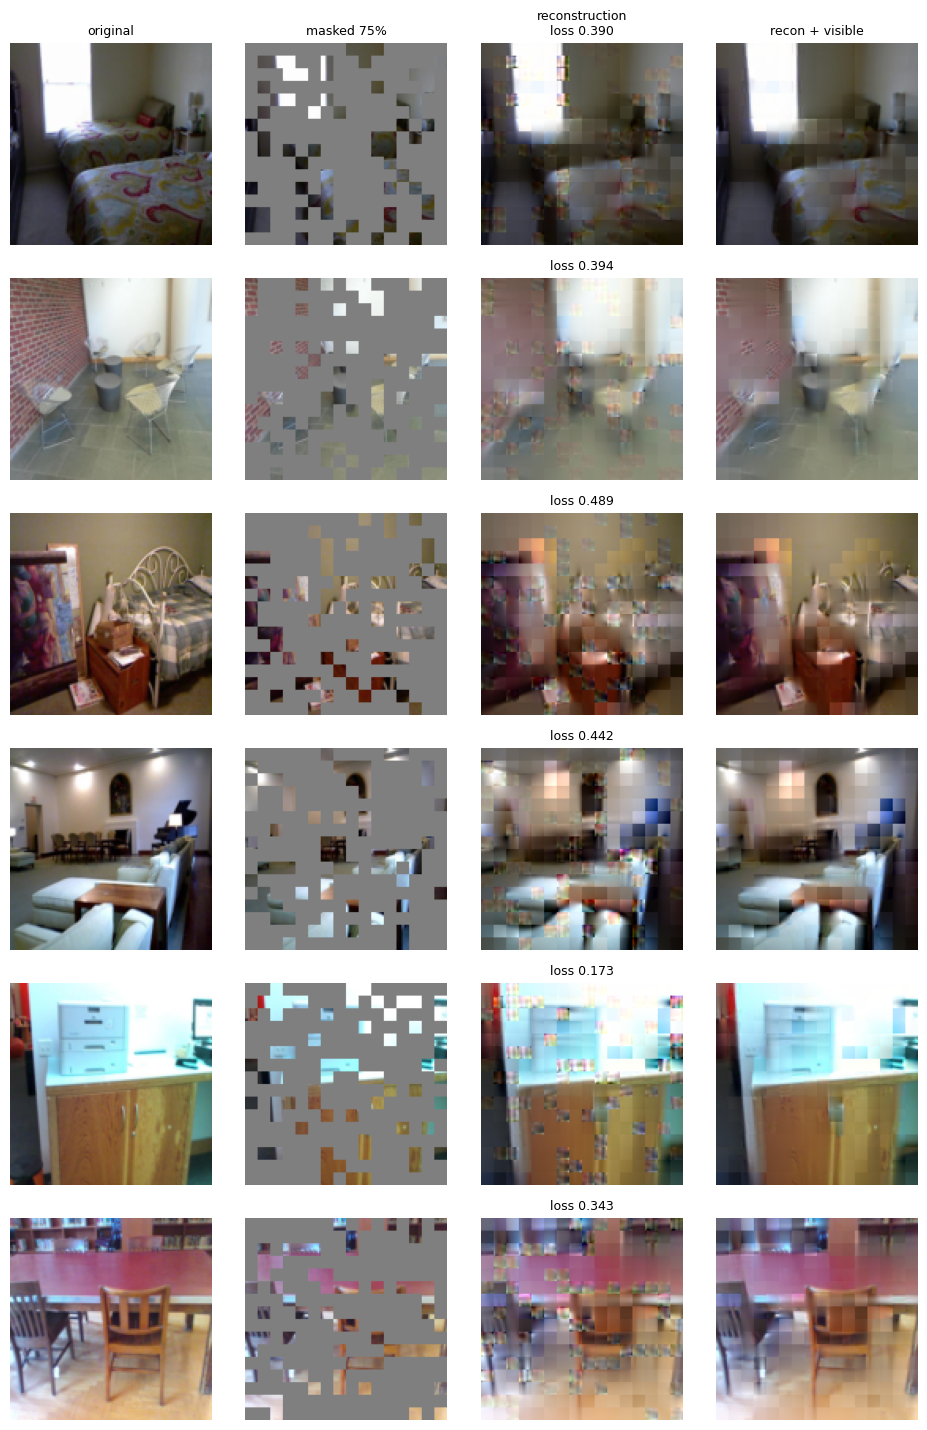

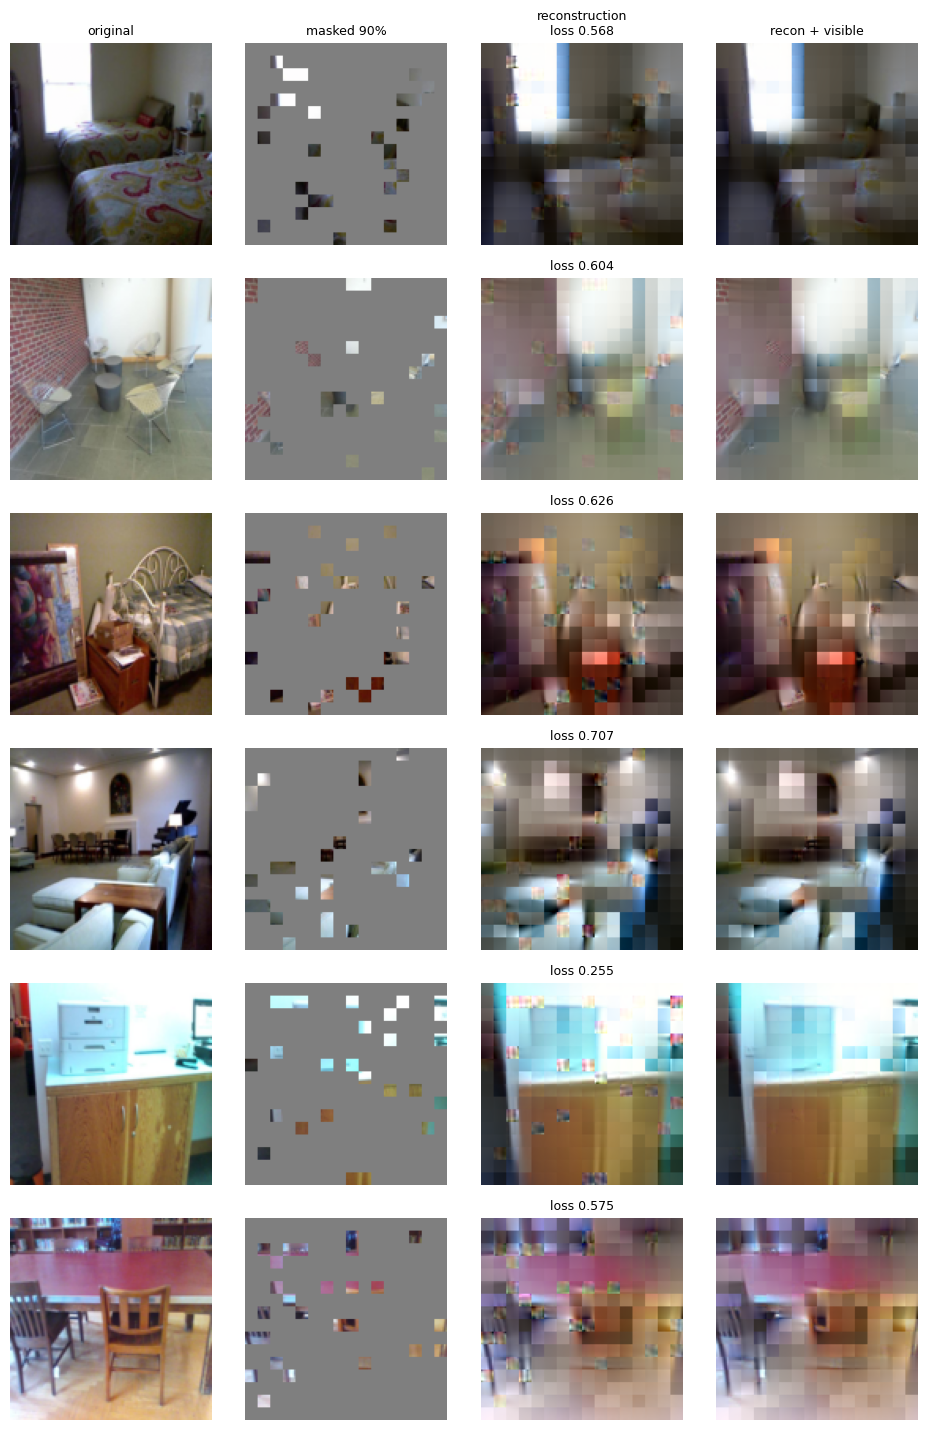

In [28]:
@torch.no_grad()
def show_reconstructions(n=6, mask_ratio=0.75, seed=0):
    was_training = model.training
    old_ratio = model.mask_ratio
    model.mask_ratio = mask_ratio
    model.eval()

    g = torch.Generator().manual_seed(seed)
    picks = torch.randperm(len(val_ds), generator=g)[:n].tolist()
    imgs = torch.stack([val_ds[k] for k in picks]).to(DEVICE)
    noise = torch.rand(n, 1, N_PATCHES, generator=g).to(DEVICE)

    with torch.autocast("cuda", dtype=AMP_DTYPE):
        _, pred, mask = model(imgs, noise)

    model.mask_ratio = old_ratio
    if was_training:
        model.train()

    pred = pred.float()
    target = model.patchify(imgs.unsqueeze(1))[:, 0]
    mean = target.mean(dim=-1, keepdim=True)
    std = (target.var(dim=-1, keepdim=True) + 1e-6) ** 0.5

    if model.norm_pix_loss:
        pred_pix = pred * std + mean
        target_norm = (target - mean) / std
    else:
        pred_pix = pred
        target_norm = target

    per_patch = ((pred - target_norm) ** 2).mean(dim=-1)
    per_image = ((per_patch * mask).sum(dim=1) / mask.sum(dim=1)).cpu()

    m = mask.unsqueeze(-1)
    p = model.patch_size
    gray = ((0.5 - MEAN.view(3)) / STD.view(3)).repeat(p * p).to(DEVICE)
    masked_in = target * (1 - m) + gray * m
    pasted = target * (1 - m) + pred_pix * m

    def to_imgs(x):
        return model.unpatchify(x.unsqueeze(1))[:, 0].cpu()

    columns = [("original", imgs.cpu()),
               (f"masked {int(mask_ratio * 100)}%", to_imgs(masked_in)),
               ("reconstruction", to_imgs(pred_pix)),
               ("recon + visible", to_imgs(pasted))]

    fig, ax = plt.subplots(n, len(columns), figsize=(2.4 * len(columns), 2.4 * n), squeeze=False)
    for r in range(n):
        for c, (title, batch) in enumerate(columns):
            ax[r, c].imshow(to_img(batch[r]))
            ax[r, c].axis("off")
            if r == 0:
                ax[r, c].set_title(title, fontsize=9)
        ax[r, 2].set_title(f"loss {per_image[r]:.3f}" if r > 0 else f"reconstruction\nloss {per_image[r]:.3f}", fontsize=9)
    plt.tight_layout()
    plt.show()


best = torch.load(BEST_PATH, map_location=DEVICE)
model.load_state_dict(best["model"])
print(f"loaded best from step {best['step']} (val {best['val']:.4f})")

show_reconstructions(n=6, mask_ratio=0.75)
show_reconstructions(n=6, mask_ratio=0.9)